<div style="padding: 10px; border-radius: 5px; border: 2px solid #73AD21; width:100%; margin:auto;">
<b> <i class="fa-solid fa-thumbtack"></i></i> Objectifs :</b>
<ul>
    <li>Mesurer une distance focale</li>
</ul>
</div>

La focométrie, ou l'art de mesurer la distance focale d'une lentille, est une discipline dont le but est de caractériser une lentille.
Comme tout exercice de métrologie, le secret de cet art est de maîtriser les incertitudes et de manipuler soigneusement !
Pour mesurer précisément la focale $f'$, trois méthodes sont proposées.
Pour chacune d'elles, il s'agira de discuter la précision de la mesure, mais aussi la difficulté et la rapidité de mise en place.

Les méthodes présentées utilise une lentille de vergence $+8\delta$ (focale $f'= 12.5$ cm).
Cette valeur n'est pas fournie aux étudiants, l'objectif du TP est de la trouver.

In [1]:
#| echo: false
import numpy as np
import matplotlib.pyplot as plt

## Méthode d'auto-collimation

<i class="fa-solid fa-gear"></i> **Matériel :**

- Une lampe (sans objet pour avoir un maximum d'intensité lumineuse);
- Un diaphragme (avoir un trou d'environ 2mm),
- un miroir plan

Mettre en oeuvre la méthode d'auto-collimation. A votre avis, quelle est l'incertitude associée à la mesure ?

<a href="../codes_applications/GEOGEBRA/autocolimation.html">
<div style="background-color:#0B0358; color:white; text-align:center; padding:20px; border-radius:8px; width:60%;margin:auto;">
Illustration de la méthode d'autocolimation avec Geogebra.
</div>
</a>

## Méthode des points conjugués

Matériel :

- Une lampe, munie d'un objet;
- Un écran
- Une lentille inconnue

Pour avoir le plus d'amplitude possible, placer la lampe à une extrémité du banc optique.

D'après la relation de conjuguaison de Descartes, les grandeurs $L=\overline{OA}$ et $L'=\overline{OA'}$ vérifient la relation :

$$
    \underbrace{LL'}_{=P}
    =f'\cdot
    \underbrace{(L-L')}_{=D}
$$
avec $P$ et $D$ correspondant respectivement au produit et à la somme de $L$ et $L'$.
L'objet reste fixe ici. 
Pour différentes positions de la lentille $L$, on ajuste la position de l'écran pour observer l'image nette, la position correspond à $L'$. 

*Remarques :*

- Attention au signe des grandeurs, $L<0$.
- Pour que l'image existe (soit réelle), l'objet doit vérifier la condition $L<f'$.

**Mesures de $L=\overline{OA}$ et $L'=\overline{OA'}$ :**
<table>
    <tr>
        <td>$L$ (cm)</td>
        <td>-14</td>
        <td>-19</td>
        <td>-24</td>
        <td>-34</td>
        <td>-39</td>
        <td>-44</td>
        <td>-49</td>
        <td>-54</td>
        <td>-59</td>
    </tr>
    <tr>
        <td>$L'$ (cm)</td>
        <td>134</td>
        <td>36.5</td>
        <td>26</td>
        <td>21.5</td>
        <td>19.5</td>
        <td>18</td>
        <td>17</td>
        <td>16.5</td>
        <td>15.5</td>
    </tr>
</table>

En traçant $P=LL'$ en fonction de $D=L-L'$, nous devons obtenir une droite de pente $f'$.

f=12.82 cm


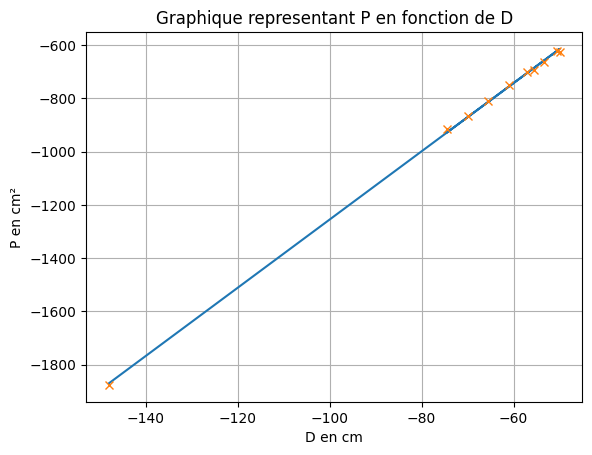

In [24]:
#| code-fold: true
L = np.array([-14,-19,-24,-29,-34,-39,-44,-49,-54,-59]) # Valeur de L
Lp = np.array([134,36.5,26,21.5,19.5,18,17,16.5,16,15.5]) # Valeur de L'

P = L*Lp
D = L-Lp

# Regression linéaire 
coef = np.polyfit(D,P,1)
plt.plot(D, coef[0]*D+coef[1])
print(f'f={coef[0]:.02f} cm')

plt.title('Graphique representant P en fonction de D')
plt.xlabel('D en cm')
plt.ylabel('P en cm²')
plt.grid()
plt.plot(D,P, 'x',label = 'P=f(D)')
plt.show()

In [28]:
# Erreur fixe de 0.1 mm
dL = 0.2
dLp = 0.2 

N = 10000
fp_simu = [] # Liste contenant les valeurs de pentes simul%*é*)es
for i in range(N):
    L_simu = np.random.normal( L, dL )
    Lp_simu = np.random.normal( Lp, dLp )
    P_simu = L_simu*Lp_simu
    D_simu = L_simu-Lp_simu
    coef = np.polyfit( D_simu, P_simu, deg=1 )
    fp_simu.append( coef[0] )
print( np.mean( fp_simu ), np.std( fp_simu ) ) # Etude statistique des pentes et affichage

12.824420527613075 0.2554059552976439


# Méthode de Bessel

Matériel :
- Une lampe, munie d'un objet;
- Un écran

On note :
- $D$ est la distance entre l'objet et l'écran; $D=\overline{AA'}=\overline{AO}+\overline{OA'}$ 
- Lorsque $D\geq4f'$, il existe deux positions de lentille pour lesquelle l'image est nette, on les notes $d_1$ et $d_2$.

1. Placer l'écran de manière à ce que l'inégalité soit vérifiée; en pratique, placer la lampe à une extrémité du banc d'optique et l'écran à l'autre extrémité.
2. Chercher les deux positions $d_1$ et $d_2$ permettant d'obtenir l'image nette à l'écran.
3. La focale est alors donnée par $f'=\frac{D^2-d^2}{4D}$, avec $d=d_1-d_2$
4. Compléter les lignes de codes suivantes.

In [23]:
# Indiquer les valeurs mesurées (en cm)
d1 = 15
d2 = 85
D = 99.5

# Entrer la formule permettant de calculer f', en utilisant les noms de variables ci-dessus
d = d1-d2
fp = (D**2-d**2)/(4*D)

print( "f'=", fp )

f'= 12.563442211055277


**Estimation de l'incertitude**

In [21]:
N = 10000 # Nombre de tirages aléatoires

d1_simu = np.random.normal( d1, 0.2, N )
d2_simu = np.random.normal( d2, 0.2, N )
D_simu = np.random.normal( D, 0.2, N )
d_simu = d1_simu-d2_simu
fp_simu = (D_simu**2-d_simu**2)/(4*D_simu)

print( np.mean(fp_simu), np.std(fp_simu) )

12.563284697552879 0.12531770595478842


## Méthode de Bessel "avancée"

Matériel :
- Une lampe, munie d'un objet;
- Un écran

D'après la partie précédente, si $D$ vérifie $D\geq4f'$ alors il existe deux positions $d_1$ et $d_2$ permettant d'obtenir l'image nette à l'écran. La focale vérifie alors :
$$4D f'=D^2-d^2$$

Pour différente position d'écran $D$, repérer $d_1$ et $d_2$. **Attention, $D$ doit toujours vérifier l'inégalité**

<table>
<tr><td>d1</td><td>13.5</td><td>13</td><td>13</td><td>13</td><td>13</td><td>13</td><td>20</td><td>16.5</td></tr>
<tr><td>d2</td><td>95</td><td>100</td><td>105</td><td>110</td><td>113</td><td>118</td><td>29.5</td><td>43</td></tr>
<tr><td>D</td><td>109</td><td>114</td><td>119</td><td>123</td><td>127</td><td>132</td><td>50</td><td>60</td></tr>
</table>

f= 11.89479628754272


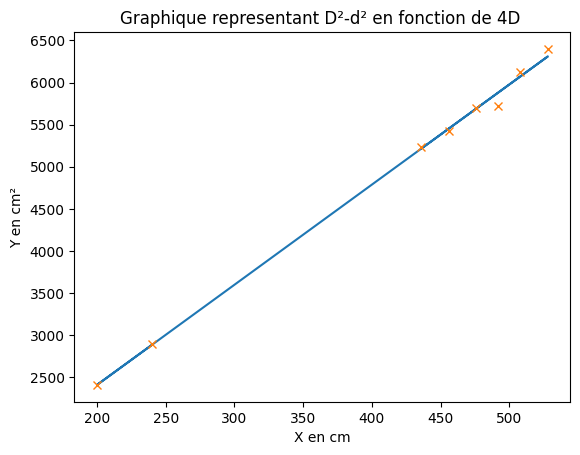

In [29]:
#| fold: true
# Valeurs mesurées
d1 = np.array([ 13.5,13,13,13,13,13,20,16.5])
d2 = np.array([ 95,100,105, 110,113,118,29.5,43])
D = np.array([109,114,119,123,127,132,50,60])

d = d1-d2 # Calcul de différence

# Ce que l'on trace; indiquer l'expression de l'abscisse et de l'ordonnée dans ce cas
Y = D**2-d**2
X = 4*D

# Regression linéaire 
coef = np.polyfit(X,Y,1)
plt.plot(X, coef[0]*X+coef[1])
print('f=',coef[0])

plt.title('Graphique representant D²-d² en fonction de 4D ')
plt.xlabel('X en cm')
plt.ylabel('Y en cm²')
plt.plot(X,Y, 'x',label = 'D²-d²=f(4D)')
plt.show()

In [31]:
# Erreur fixe de 0.1 mm
dd1 = 0.2
dd2 = 0.2
dD= 0.3

N = 10000

fp_simu = [] # Liste contenant les valeurs de pentes simul%*é*)es
for i in range(N):
    d1_simu = np.random.normal( d1, dd2 )
    d2_simu = np.random.normal( d2, dd2 )
    D_simu = np.random.normal( D, dD )

    Y_simu = D_simu**2-(d1_simu-d2_simu)**2
    X_simu = 4*D_simu
    
    coef = np.polyfit( X_simu, Y_simu, deg=1 )
    fp_simu.append( coef[0] )
print( np.mean( fp_simu ), np.std( fp_simu ) ) # Etude statistique des pentes et affichage

11.894844052746027 0.14269901240990365


## Conclusion

Comparer les trois mesures. Laquelle est la plus précise ? et la plus rapide ? Dans quel cas utiliser l'une ou l'autre ? ...

<table>
    <tr>
        <td>Méthode</td>
        <td>$f'$</td>
        <td>Incertitude</td>
    </tr>
    <tr>
        <td>Autocolimation</td>
        <td>12.0</td>
        <td>0.5</td>
    </tr>
    <tr>
        <td>Points conjugués</td>
        <td>12.82</td>
        <td>0.25</td>
    </tr>
    <tr>
        <td>Méthode de Bessel</td>
        <td>12.56</td>
        <td>0.13</td>
    </tr>
    <tr>
        <td>Méthode de Bessel "avancée"</td>
        <td>11.89</td>
        <td>0.14</td>
    </tr>
</table>